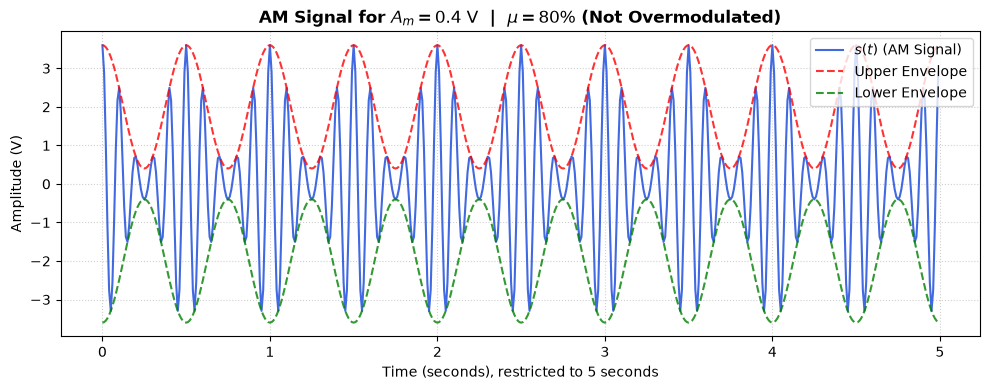

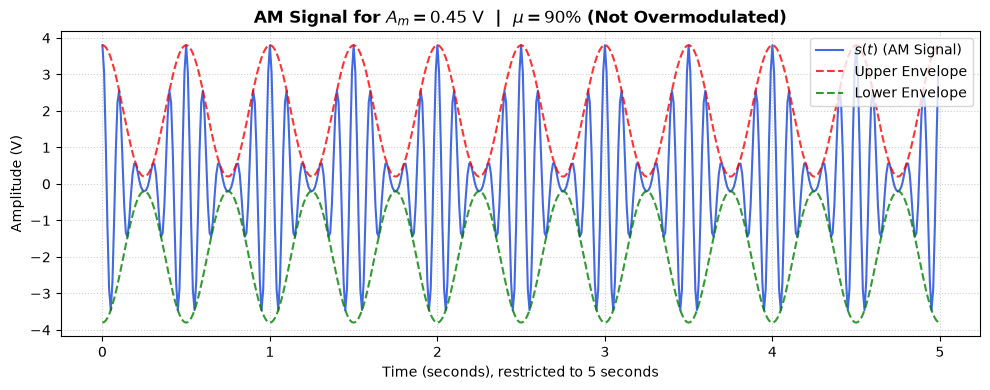

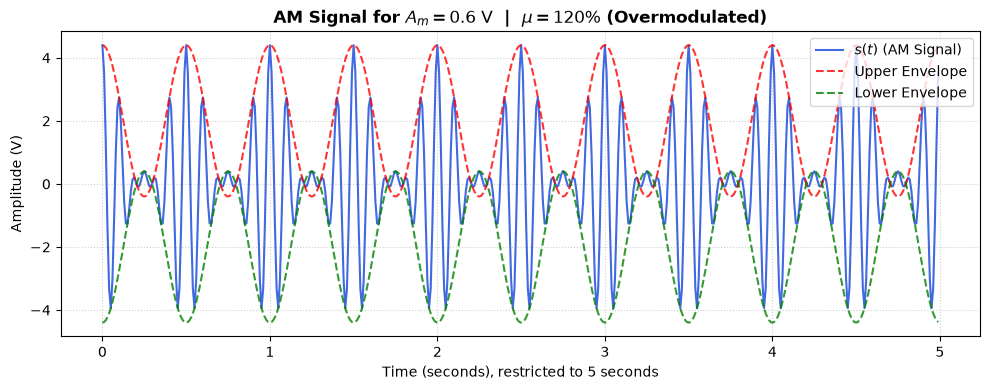

In [11]:
# q2
import matplotlib.pyplot as plt
import numpy as np

Ac = 2.0  # Carrier amplitude 
fc = 10.0  # Carrier frequency 
fm = 2.0  # Message frequency 
ka = 2.0  # Amplitude sensitivity 
fs = 100.0  # Sampling rate 
N = 2000  # Total samples

t = np.arange(N) / fs

Am_values = [0.4, 0.45, 0.6]

for Am in Am_values:
    # Message signal
    m_t = Am * np.cos(2 * np.pi * fm * t)

    s_t = Ac * (1 + ka * m_t) * np.cos(2 * np.pi * fc * t)

    # Modulation envelope
    envelope_upper = Ac * (1 + ka * m_t)
    envelope_lower = -envelope_upper

    mu = ka * Am
    mu_pct = mu * 100
    is_overmodulated = mu > 1.0

    plot_samples = (N//4) # note: this is spliced to show graph better, but you could remove the
    # //4 to show the entire spectrum. it repeats anyway 

    plt.figure(figsize=(10, 4), dpi=100)
    plt.plot(
        t[:plot_samples],
        s_t[:plot_samples],
        label="$s(t)$ (AM Signal)",
        color="royalblue",
        lw=1.5,
    )
    plt.plot(
        t[:plot_samples],
        envelope_upper[:plot_samples],
        "r--",
        label="Upper Envelope",
        alpha=0.8,
    )
    plt.plot(
        t[:plot_samples],
        envelope_lower[:plot_samples],
        "g--",
        label="Lower Envelope",
        alpha=0.8,
    )

    status_str = "Overmodulated" if is_overmodulated else "Not Overmodulated"
    plt.title(
        f"AM Signal for $A_m = {Am}\\text{{ V}}$  |  $\\mu = {mu_pct:.0f}\\%$ ({status_str})",
        fontsize=12,
        fontweight="bold",
    )
    plt.xlabel("Time (seconds), restricted to 5 seconds", fontsize=10)
    plt.ylabel("Amplitude (V)", fontsize=10)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


Fixed threshold rho = 4.29193

=== (c)-(d) Nominal: $\sigma^2 = 1$ (0 dB) ===
  Time to generate and process 1e+07 samples: 0.38 s
  Exceedance count: 1009 / 10000000
  Empirical P(R > rho):  1.00900e-04
  Theoretical P(R > rho): 1.00000e-04
  Relative error:        0.90%

=== (e) Decreased: $\sigma^2 = -1\text{ dB}$ ===
  Time to generate and process 1e+07 samples: 0.36 s
  Exceedance count: 110 / 10000000
  Empirical P(R > rho):  1.10000e-05
  Theoretical P(R > rho): 9.21082e-06
  Relative error:        19.42%

=== (f) Increased: $\sigma^2 = +1\text{ dB}$ ===
  Time to generate and process 1e+07 samples: 0.37 s
  Exceedance count: 6623 / 10000000
  Empirical P(R > rho):  6.62300e-04
  Theoretical P(R > rho): 6.64794e-04
  Relative error:        0.38%



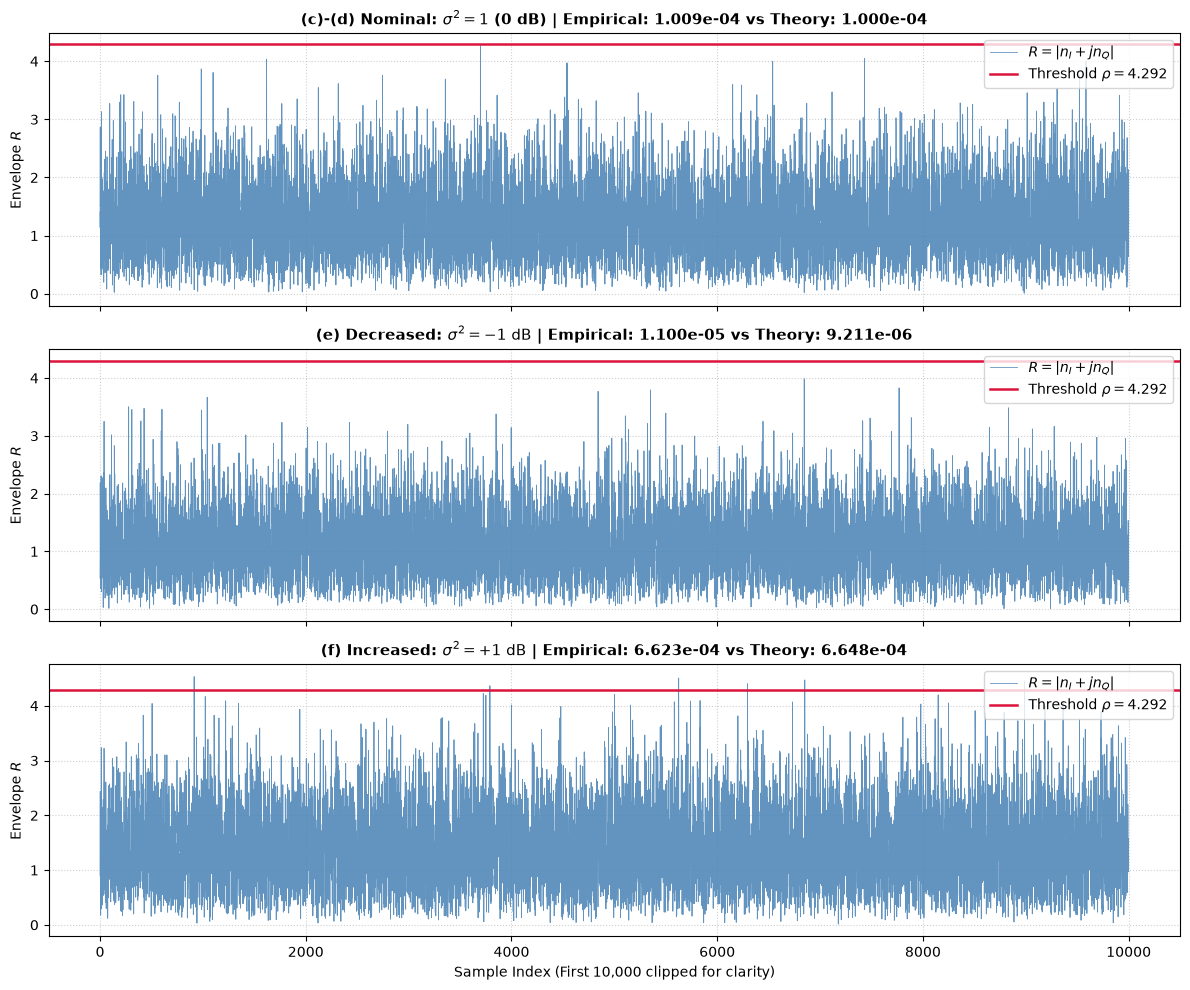

In [15]:
# q3c

import time
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(31415)

N = 10000000  
sigma_0 = 1.0
rho = np.sqrt(8 * np.log(10)) * sigma_0  

print(f"Fixed threshold rho = {rho:.5f}\n")

experiments = [
    {
        "label": "(c)-(d) Nominal: $\\sigma^2 = 1$ (0 dB)",
        "sigma2": 1.0,
        "P_theory": 1.0e-4,
    },
    {
        "label": "(e) Decreased: $\\sigma^2 = -1\\text{ dB}$",
        "sigma2": 10 ** (-0.1),
        "P_theory": np.exp(-(rho**2) / (2 * 10 ** (-0.1))),
    },
    {
        "label": "(f) Increased: $\\sigma^2 = +1\\text{ dB}$",
        "sigma2": 10 ** (+0.1),
        "P_theory": np.exp(-(rho**2) / (2 * 10 ** (+0.1))),
    },
]

# Run simulations and plot
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)


plot_points = 10000 # same concept as before

for idx, exp in enumerate(experiments):
    sigma = np.sqrt(exp["sigma2"])

    t0 = time.time()
    n_I = np.random.normal(0, sigma, N)
    n_Q = np.random.normal(0, sigma, N)
    R = np.sqrt(n_I**2 + n_Q**2)
    elapsed = time.time() - t0

    # fraction o f time
    exceedances = np.sum(R > rho)
    frac_exceeded = exceedances / N

    print(f"=== {exp['label']} ===")
    print(f"  Time to generate and process {N:.0e} samples: {elapsed:.2f} s")
    print(f"  Exceedance count: {exceedances} / {N}")
    print(f"  Empirical P(R > rho):  {frac_exceeded:.5e}")
    print(f"  Theoretical P(R > rho): {exp['P_theory']:.5e}")
    print(f"  Relative error:        {abs(frac_exceeded - exp['P_theory']) / exp['P_theory'] * 100:.2f}%\n")

    ax = axes[idx]
    ax.plot(
        R[:plot_points],
        color="steelblue",
        lw=0.6,
        alpha=0.85,
        label=r"$R = |n_I + j n_Q|$",
    )
    ax.axhline(
        rho,
        color="crimson",
        linestyle="-",
        lw=1.8,
        label=rf"Threshold $\rho = {rho:.3f}$",
    )

    ax.set_title(
        f"{exp['label']} | Empirical: {frac_exceeded:.3e} vs Theory: {exp['P_theory']:.3e}",
        fontsize=11,
        fontweight="bold",
    )
    ax.set_ylabel("Envelope $R$", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right")

axes[-1].set_xlabel(
    f"Sample Index (First {plot_points:,} clipped for clarity)", fontsize=10
)
plt.tight_layout()
plt.show()